# Challenge Avanzado: Predicción de Riesgo de Automatización Laboral en Jalisco
## Análisis de Big Data con PySpark y Machine Learning

**Autor:** Carlos Pulido Rosas

**Universidad:** Universidad de Guadalajara - Campus CUCEA

**Maestria:** Ciencia de los Datos

**Materia:** Procesamiento de Grandes Bases de Datos

**Tema de Tesis:** Predicción de Riesgo de Automatización Laboral por IA en Jalisco, México (2025-2030)

---

## Descripción del Proyecto

Este proyecto integra **PySpark**, **Spark MLlib** y **análisis de datos del Banco Mundial** para crear un sistema predictivo que evalúa el riesgo de automatización de diferentes ocupaciones en el contexto mexicano, con enfoque específico en Jalisco.

### Objetivos

1. **Integrar múltiples fuentes de datos:** Banco Mundial, O*NET, ENOE México
2. **Construir modelo predictivo avanzado** de riesgo de automatización
3. **Identificar ocupaciones vulnerables** en Jalisco
4. **Generar recomendaciones** de política pública y capacitación
5. **Aplicar técnicas avanzadas de PySpark:** MLlib, Feature Engineering, Pipelines

### Fuentes de Datos

- **Banco Mundial:** Indicadores de empleo, tecnología, educación (API)
- **O*NET Database:** Características de ocupaciones, habilidades requeridas
- **ENOE (simulado):** Estructura laboral de Jalisco
- **Investigación académica:** Índices de automatización (Frey & Osborne, 2013)

### Metodología

1. **Descarga y preparación** de datos con APIs
2. **Feature engineering** avanzado con PySpark
3. **Modelos de ML:** Random Forest, Gradient Boosting, Regresión
4. **Validación cruzada** y optimización de hiperparámetros
5. **Análisis de impacto** por sector económico
6. **Visualizaciones interactivas** y dashboard

## 1. Configuración del Entorno

In [1]:
# Importar librerías principales
import pyspark.pandas as ps
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.window import Window

# Spark MLlib
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder
from pyspark.ml.feature import PCA, Bucketizer, QuantileDiscretizer
from pyspark.ml.regression import RandomForestRegressor, GBTRegressor, LinearRegression
from pyspark.ml.classification import RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import RegressionEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml import Pipeline

# Visualización y análisis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# APIs y utilidades
import requests
import json
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Configurar estilo
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)

print("✓ Librerías importadas exitosamente")
print(f"Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

c:\Users\carlo\anaconda3\envs\ai_automation_thesis\lib\site-packages\pyspark\pandas\__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


✓ Librerías importadas exitosamente
Fecha de ejecución: 2025-11-29 07:25:21


In [2]:
# Crear sesión de Spark optimizada para análisis complejo
spark = SparkSession.builder \
    .appName("AI_Automation_Risk_Jalisco") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .config("spark.sql.shuffle.partitions", "8") \
    .config("spark.default.parallelism", "8") \
    .master("local[*]") \
    .getOrCreate()

# Configurar nivel de log
spark.sparkContext.setLogLevel("ERROR")

# Configurar PySpark.Pandas
ps.set_option('compute.default_index_type', 'distributed')
ps.set_option('compute.ops_on_diff_frames', True)

print("✓ Sesión de Spark configurada")
print(f"Versión de Spark: {spark.version}")
print(f"Cores disponibles: {spark.sparkContext.defaultParallelism}")
print(f"Master: {spark.sparkContext.master}")

✓ Sesión de Spark configurada
Versión de Spark: 3.5.6
Cores disponibles: 8
Master: local[*]


## 2. Descarga de Datos del Banco Mundial (API)

In [3]:
# Función para descargar datos del Banco Mundial
def descargar_indicador_bm(indicador, pais='MX', fecha_inicio=2010, fecha_fin=2023):
    """
    Descarga datos del Banco Mundial usando su API
    
    Parámetros:
    - indicador: Código del indicador (ej: 'SL.UEM.TOTL.ZS' para desempleo)
    - pais: Código ISO del país (MX = México)
    - fecha_inicio: Año inicial
    - fecha_fin: Año final
    """
    url = f"https://api.worldbank.org/v2/country/{pais}/indicator/{indicador}"
    params = {
        'date': f'{fecha_inicio}:{fecha_fin}',
        'format': 'json',
        'per_page': 500
    }
    
    try:
        response = requests.get(url, params=params)
        data = response.json()
        
        if len(data) > 1 and data[1]:
            records = []
            for item in data[1]:
                if item['value'] is not None:
                    records.append({
                        'indicador': indicador,
                        'indicador_nombre': item['indicator']['value'],
                        'pais': item['country']['value'],
                        'año': int(item['date']),
                        'valor': float(item['value'])
                    })
            return pd.DataFrame(records)
        else:
            print(f"⚠️ No hay datos para {indicador}")
            return pd.DataFrame()
    except Exception as e:
        print(f"❌ Error descargando {indicador}: {e}")
        return pd.DataFrame()

print("✓ Función de descarga definida")

✓ Función de descarga definida


In [4]:
# Indicadores relevantes del Banco Mundial para análisis de automatización
indicadores_bm = {
    'SL.UEM.TOTL.ZS': 'Desempleo total (% fuerza laboral)',
    'SL.TLF.TOTL.IN': 'Fuerza laboral total',
    'SE.TER.ENRR': 'Tasa de matriculación terciaria',
    'SE.SEC.ENRR': 'Tasa de matriculación secundaria',
    'GB.XPD.RSDV.GD.ZS': 'Gasto en I+D (% PIB)',
    'IT.NET.USER.ZS': 'Usuarios de Internet (% población)',
    'NY.GDP.PCAP.CD': 'PIB per cápita (USD)',
    'SP.POP.TOTL': 'Población total',
    'SL.IND.EMPL.ZS': 'Empleo en industria (% empleo total)',
    'SL.SRV.EMPL.ZS': 'Empleo en servicios (% empleo total)',
    'SL.AGR.EMPL.ZS': 'Empleo en agricultura (% empleo total)'
}

print("Descargando datos del Banco Mundial...")
print("-" * 80)

dfs_bm = []
for codigo, nombre in indicadores_bm.items():
    print(f"Descargando: {nombre}...")
    df_temp = descargar_indicador_bm(codigo)
    if not df_temp.empty:
        dfs_bm.append(df_temp)
        print(f"  ✓ {len(df_temp)} registros descargados")
    else:
        print(f"  ⚠️ Sin datos")

# Combinar todos los datos
if dfs_bm:
    df_banco_mundial = pd.concat(dfs_bm, ignore_index=True)
    print(f"\n✓ Total de registros del Banco Mundial: {len(df_banco_mundial):,}")
else:
    print("⚠️ No se pudieron descargar datos del Banco Mundial")
    df_banco_mundial = pd.DataFrame()

Descargando datos del Banco Mundial...
--------------------------------------------------------------------------------
Descargando: Desempleo total (% fuerza laboral)...
  ✓ 14 registros descargados
Descargando: Fuerza laboral total...
  ✓ 14 registros descargados
Descargando: Tasa de matriculación terciaria...
  ✓ 14 registros descargados
Descargando: Tasa de matriculación secundaria...
  ✓ 14 registros descargados
Descargando: Gasto en I+D (% PIB)...
  ✓ 14 registros descargados
Descargando: Usuarios de Internet (% población)...
  ✓ 14 registros descargados
Descargando: PIB per cápita (USD)...
  ✓ 14 registros descargados
Descargando: Población total...
  ✓ 14 registros descargados
Descargando: Empleo en industria (% empleo total)...
  ✓ 14 registros descargados
Descargando: Empleo en servicios (% empleo total)...
  ✓ 14 registros descargados
Descargando: Empleo en agricultura (% empleo total)...
  ✓ 14 registros descargados

✓ Total de registros del Banco Mundial: 154


In [5]:
# Pivotar datos para tener indicadores como columnas
if not df_banco_mundial.empty:
    df_bm_pivot = df_banco_mundial.pivot_table(
        index=['pais', 'año'],
        columns='indicador',
        values='valor',
        aggfunc='first'
    ).reset_index()
    
    # Renombrar columnas a nombres más legibles
    nombre_columnas = {
        'SL.UEM.TOTL.ZS': 'desempleo_pct',
        'SL.TLF.TOTL.IN': 'fuerza_laboral',
        'SE.TER.ENRR': 'educacion_terciaria_pct',
        'SE.SEC.ENRR': 'educacion_secundaria_pct',
        'GB.XPD.RSDV.GD.ZS': 'gasto_id_pct_pib',
        'IT.NET.USER.ZS': 'usuarios_internet_pct',
        'NY.GDP.PCAP.CD': 'pib_per_capita',
        'SP.POP.TOTL': 'poblacion_total',
        'SL.IND.EMPL.ZS': 'empleo_industria_pct',
        'SL.SRV.EMPL.ZS': 'empleo_servicios_pct',
        'SL.AGR.EMPL.ZS': 'empleo_agricultura_pct'
    }
    
    df_bm_pivot.rename(columns=nombre_columnas, inplace=True)
    
    print("✓ Datos pivotados")
    print(f"Dimensiones: {df_bm_pivot.shape}")
    print(f"\nColumnas disponibles:")
    for col in df_bm_pivot.columns:
        print(f"  - {col}")
    
    # Mostrar muestra
    print("\nPrimeras filas:")
    display(df_bm_pivot.head())
else:
    df_bm_pivot = pd.DataFrame()

✓ Datos pivotados
Dimensiones: (14, 13)

Columnas disponibles:
  - pais
  - año
  - gasto_id_pct_pib
  - usuarios_internet_pct
  - pib_per_capita
  - educacion_secundaria_pct
  - educacion_terciaria_pct
  - empleo_agricultura_pct
  - empleo_industria_pct
  - empleo_servicios_pct
  - fuerza_laboral
  - desempleo_pct
  - poblacion_total

Primeras filas:


indicador,pais,año,gasto_id_pct_pib,usuarios_internet_pct,pib_per_capita,educacion_secundaria_pct,educacion_terciaria_pct,empleo_agricultura_pct,empleo_industria_pct,empleo_servicios_pct,fuerza_laboral,desempleo_pct,poblacion_total
0,Mexico,2010,0.47353,31.0500,9728.800782,87.272926,27.167021,14.635556,23.037763,62.326680,48189452.0,5.303,113623895.0
1,Mexico,2011,0.45268,37.1763,10664.494405,88.380089,28.036160,14.222824,23.081354,62.695822,49262430.0,5.175,115243504.0
2,Mexico,2012,0.40284,39.7500,10744.133523,90.693619,29.349649,14.278846,22.923986,62.797167,50764169.0,4.892,116818208.0
3,Mexico,2013,0.40806,43.4600,11216.800852,93.262306,30.330160,14.197783,23.246816,62.555401,51511392.0,4.921,118343573.0
4,Mexico,2014,0.41962,44.3857,11391.377351,97.319687,31.205290,14.301130,23.708193,61.990675,51907743.0,4.819,119784261.0


## 3. Generación de Datos Sintéticos de Ocupaciones (Basados en O*NET y ENOE)

In [6]:
# Crear dataset sintético de ocupaciones en Jalisco
# Basado en estructura de O*NET y estadísticas de ENOE

np.random.seed(42)

# Ocupaciones principales en Jalisco (basado en ENOE)
ocupaciones_jalisco = [
    # Tecnología e Informática
    ('Desarrollador de Software', 'Tecnología', 85000, 0.25, 8.5, 7.2, 9.1, 3.5),
    ('Analista de Datos', 'Tecnología', 75000, 0.30, 8.8, 7.5, 8.9, 4.2),
    ('Ingeniero en Sistemas', 'Tecnología', 80000, 0.28, 8.3, 7.0, 8.7, 3.8),
    ('Técnico en Soporte IT', 'Tecnología', 35000, 0.65, 5.5, 6.8, 4.2, 7.5),
    
    # Manufactura (Jalisco es hub manufacturero)
    ('Operador de Maquinaria', 'Manufactura', 25000, 0.85, 3.2, 7.8, 2.1, 8.9),
    ('Ensamblador Electrónico', 'Manufactura', 28000, 0.80, 3.8, 7.5, 2.5, 8.5),
    ('Supervisor de Producción', 'Manufactura', 45000, 0.50, 6.2, 6.5, 5.8, 5.2),
    ('Ingeniero Industrial', 'Manufactura', 65000, 0.35, 7.8, 6.2, 7.5, 4.5),
    ('Control de Calidad', 'Manufactura', 38000, 0.60, 5.5, 6.8, 4.8, 6.2),
    
    # Comercio y Servicios
    ('Cajero', 'Comercio', 18000, 0.90, 2.5, 8.5, 1.8, 9.2),
    ('Vendedor', 'Comercio', 20000, 0.75, 3.8, 7.2, 3.5, 7.8),
    ('Gerente de Tienda', 'Comercio', 35000, 0.45, 5.8, 5.5, 6.2, 4.8),
    ('Asesor de Ventas', 'Comercio', 25000, 0.55, 4.5, 6.8, 4.2, 6.5),
    
    # Salud
    ('Médico General', 'Salud', 95000, 0.15, 9.5, 3.2, 9.8, 2.1),
    ('Enfermero', 'Salud', 32000, 0.35, 7.2, 5.5, 7.8, 4.5),
    ('Técnico Radiólogo', 'Salud', 42000, 0.40, 6.8, 6.2, 6.5, 5.8),
    ('Farmacéutico', 'Salud', 48000, 0.50, 7.5, 5.8, 6.8, 5.5),
    
    # Educación
    ('Profesor de Primaria', 'Educación', 28000, 0.20, 8.2, 3.5, 8.5, 2.8),
    ('Profesor Universitario', 'Educación', 55000, 0.18, 9.0, 2.8, 9.2, 2.2),
    ('Tutor Privado', 'Educación', 22000, 0.25, 7.5, 4.2, 7.8, 3.5),
    
    # Transporte y Logística
    ('Conductor de Transporte', 'Transporte', 22000, 0.88, 2.8, 8.8, 2.2, 9.5),
    ('Almacenista', 'Transporte', 20000, 0.82, 3.2, 8.2, 2.5, 8.8),
    ('Coordinador Logístico', 'Transporte', 42000, 0.55, 6.5, 5.8, 6.2, 5.5),
    
    # Construcción
    ('Albañil', 'Construcción', 24000, 0.70, 3.5, 8.0, 2.8, 8.2),
    ('Electricista', 'Construcción', 32000, 0.60, 5.2, 7.2, 4.5, 7.0),
    ('Arquitecto', 'Construcción', 58000, 0.30, 8.0, 4.5, 7.8, 3.8),
    
    # Administración y Finanzas
    ('Contador', 'Finanzas', 42000, 0.55, 7.0, 5.8, 6.8, 5.2),
    ('Analista Financiero', 'Finanzas', 65000, 0.45, 7.8, 5.2, 7.5, 4.5),
    ('Asistente Administrativo', 'Administración', 22000, 0.70, 4.2, 7.5, 3.8, 7.2),
    ('Gerente de RRHH', 'Administración', 55000, 0.38, 7.5, 4.8, 7.2, 4.2),
    
    # Agricultura (importante en Jalisco)
    ('Agricultor', 'Agricultura', 18000, 0.65, 2.8, 8.5, 2.2, 8.8),
    ('Agrónomo', 'Agricultura', 45000, 0.35, 7.5, 5.2, 7.0, 4.8),
    
    # Creatividad y Medios
    ('Diseñador Gráfico', 'Creatividad', 32000, 0.40, 7.8, 5.5, 7.2, 5.0),
    ('Fotógrafo', 'Creatividad', 28000, 0.45, 7.2, 6.0, 6.8, 5.5),
    ('Editor de Video', 'Creatividad', 38000, 0.48, 7.5, 5.8, 7.0, 5.2),
    
    # Servicios Personales
    ('Estilista', 'Servicios', 20000, 0.55, 4.5, 7.0, 4.0, 7.5),
    ('Chef', 'Servicios', 35000, 0.50, 6.5, 6.2, 5.8, 6.0),
    ('Mesero', 'Servicios', 16000, 0.80, 2.5, 8.2, 2.2, 8.5),
]

# Crear DataFrame
df_ocupaciones = pd.DataFrame(ocupaciones_jalisco, columns=[
    'ocupacion', 'sector', 'salario_promedio', 'riesgo_automatizacion',
    'nivel_educacion_requerido', 'rutinidad_tareas', 
    'creatividad_requerida', 'trabajo_manual'
])

print(f"✓ Dataset de ocupaciones creado: {len(df_ocupaciones)} ocupaciones")
print(f"\nSectores incluidos: {df_ocupaciones['sector'].nunique()}")
print(df_ocupaciones['sector'].value_counts())

✓ Dataset de ocupaciones creado: 38 ocupaciones

Sectores incluidos: 12
sector
Manufactura       5
Tecnología        4
Comercio          4
Salud             4
Educación         3
Transporte        3
Construcción      3
Creatividad       3
Servicios         3
Finanzas          2
Administración    2
Agricultura       2
Name: count, dtype: int64


In [7]:
# Generar datos adicionales por ocupación
np.random.seed(42)

# Expandir cada ocupación con múltiples registros (simulando encuestas)
registros_expandidos = []

for idx, row in df_ocupaciones.iterrows():
    # Generar entre 500-2000 registros por ocupación
    n_registros = np.random.randint(500, 2000)
    
    for _ in range(n_registros):
        # Agregar variabilidad realista
        registro = {
            'ocupacion': row['ocupacion'],
            'sector': row['sector'],
            'salario_mensual': np.random.normal(row['salario_promedio'], row['salario_promedio'] * 0.2),
            'riesgo_automatizacion': np.clip(np.random.normal(row['riesgo_automatizacion'], 0.1), 0, 1),
            'nivel_educacion': np.clip(np.random.normal(row['nivel_educacion_requerido'], 0.5), 1, 10),
            'rutinidad': np.clip(np.random.normal(row['rutinidad_tareas'], 0.5), 1, 10),
            'creatividad': np.clip(np.random.normal(row['creatividad_requerida'], 0.5), 1, 10),
            'manual': np.clip(np.random.normal(row['trabajo_manual'], 0.5), 1, 10),
            'experiencia_años': np.random.exponential(5),
            'edad': np.random.normal(35, 10),
            'usa_computadora': np.random.choice([0, 1], p=[0.3, 0.7]),
            'capacitacion_reciente': np.random.choice([0, 1], p=[0.6, 0.4]),
            'zona': np.random.choice(['ZMG', 'Interior'], p=[0.7, 0.3]),
            'año': np.random.choice([2022, 2023, 2024])
        }
        registros_expandidos.append(registro)

df_ocupaciones_expandido = pd.DataFrame(registros_expandidos)

print(f"✓ Dataset expandido creado: {len(df_ocupaciones_expandido):,} registros")
print(f"\nDistribución por sector:")
print(df_ocupaciones_expandido['sector'].value_counts())
print(f"\nRango de años: {df_ocupaciones_expandido['año'].min()} - {df_ocupaciones_expandido['año'].max()}")

✓ Dataset expandido creado: 50,335 registros

Distribución por sector:
sector
Manufactura       7323
Tecnología        6130
Salud             5009
Comercio          4820
Transporte        4795
Creatividad       4154
Construcción      3799
Administración    3329
Agricultura       2899
Finanzas          2719
Servicios         2708
Educación         2650
Name: count, dtype: int64

Rango de años: 2022 - 2024


## 4. Conversión a PySpark y Feature Engineering

In [8]:
# Convertir a PySpark DataFrame
print("Convirtiendo a PySpark DataFrame...")

df_spark = spark.createDataFrame(df_ocupaciones_expandido)

print(f"✓ Conversión completada")
print(f"  Total de registros: {df_spark.count():,}")
print(f"  Total de columnas: {len(df_spark.columns)}")

# Mostrar esquema
print("\nEsquema del DataFrame:")
df_spark.printSchema()

Convirtiendo a PySpark DataFrame...
✓ Conversión completada
  Total de registros: 50,335
  Total de columnas: 14

Esquema del DataFrame:
root
 |-- ocupacion: string (nullable = true)
 |-- sector: string (nullable = true)
 |-- salario_mensual: double (nullable = true)
 |-- riesgo_automatizacion: double (nullable = true)
 |-- nivel_educacion: double (nullable = true)
 |-- rutinidad: double (nullable = true)
 |-- creatividad: double (nullable = true)
 |-- manual: double (nullable = true)
 |-- experiencia_años: double (nullable = true)
 |-- edad: double (nullable = true)
 |-- usa_computadora: integer (nullable = true)
 |-- capacitacion_reciente: integer (nullable = true)
 |-- zona: string (nullable = true)
 |-- año: integer (nullable = true)



In [10]:
# Feature Engineering Avanzado

# Importar funciones necesarias
from pyspark.sql.functions import col, when, avg, sum as spark_sum, count

print("Creando features adicionales...")
print("-" * 80)

# 1. Índice de Tecnología (combinación de educación + uso computadora)
df_spark = df_spark.withColumn(
    'indice_tecnologia',
    (col('nivel_educacion') * 0.6 + col('usa_computadora') * 4.0) / 2
)

# 2. Índice de Adaptabilidad (creatividad + capacitación reciente - rutinidad)
df_spark = df_spark.withColumn(
    'indice_adaptabilidad',
    (col('creatividad') + col('capacitacion_reciente') * 5 - col('rutinidad')) / 2
)

# 3. Categoría de Salario
df_spark = df_spark.withColumn(
    'categoria_salario',
    when(col('salario_mensual') < 20000, 'Bajo')
    .when((col('salario_mensual') >= 20000) & (col('salario_mensual') < 40000), 'Medio')
    .when((col('salario_mensual') >= 40000) & (col('salario_mensual') < 60000), 'Medio-Alto')
    .otherwise('Alto')
)

# 4. Categoría de Edad
df_spark = df_spark.withColumn(
    'grupo_edad',
    when(col('edad') < 25, 'Joven')
    .when((col('edad') >= 25) & (col('edad') < 40), 'Adulto')
    .when((col('edad') >= 40) & (col('edad') < 55), 'Adulto Mayor')
    .otherwise('Senior')
)

# 5. Indicador de Vulnerabilidad (riesgo > 0.7)
df_spark = df_spark.withColumn(
    'alta_vulnerabilidad',
    when(col('riesgo_automatizacion') > 0.7, 1).otherwise(0)
)

# 6. Categoría de Riesgo
df_spark = df_spark.withColumn(
    'categoria_riesgo',
    when(col('riesgo_automatizacion') < 0.3, 'Bajo')
    .when((col('riesgo_automatizacion') >= 0.3) & (col('riesgo_automatizacion') < 0.7), 'Medio')
    .otherwise('Alto')
)

# 7. Interacción: Educación × Tecnología
df_spark = df_spark.withColumn(
    'educacion_x_tecnologia',
    col('nivel_educacion') * col('indice_tecnologia')
)

# 8. Score de Empleabilidad Futura
df_spark = df_spark.withColumn(
    'empleabilidad_futura',
    (
        col('nivel_educacion') * 0.3 +
        col('creatividad') * 0.3 +
        col('indice_tecnologia') * 0.2 +
        col('capacitacion_reciente') * 2.0 -
        col('rutinidad') * 0.2
    )
)

print("✓ Features creados:")
print("  1. indice_tecnologia")
print("  2. indice_adaptabilidad")
print("  3. categoria_salario")
print("  4. grupo_edad")
print("  5. alta_vulnerabilidad")
print("  6. categoria_riesgo")
print("  7. educacion_x_tecnologia")
print("  8. empleabilidad_futura")

print(f"\nTotal de columnas ahora: {len(df_spark.columns)}")

Creando features adicionales...
--------------------------------------------------------------------------------
✓ Features creados:
  1. indice_tecnologia
  2. indice_adaptabilidad
  3. categoria_salario
  4. grupo_edad
  5. alta_vulnerabilidad
  6. categoria_riesgo
  7. educacion_x_tecnologia
  8. empleabilidad_futura

Total de columnas ahora: 22


In [11]:
# Mostrar estadísticas de features creados
print("Estadísticas de nuevos features:")
df_spark.select(
    'indice_tecnologia', 'indice_adaptabilidad', 
    'empleabilidad_futura', 'riesgo_automatizacion'
).summary().show()

Estadísticas de nuevos features:
+-------+------------------+--------------------+--------------------+---------------------+
|summary| indice_tecnologia|indice_adaptabilidad|empleabilidad_futura|riesgo_automatizacion|
+-------+------------------+--------------------+--------------------+---------------------+
|  count|             50335|               50335|               50335|                50335|
|   mean| 3.190414116166084|  0.5363963101380478|  3.6018845830516923|   0.5293217509215411|
| stddev|1.1231773557759264|  2.1851110901173674|  1.9709028853356336|  0.22562033616168606|
|    min|               0.3|  -4.409320064102105|  -1.077579071739037|                  0.0|
|    25%| 2.420684184280709| -0.9674834622502972|  2.1597899021428226|   0.3589825783050911|
|    50%|3.3004831128334007|  0.6007489120264209|   3.796104049600696|   0.5191793885700468|
|    75%| 4.185209376257495|  2.1667551056366907|   4.990022395210095|   0.6983432660901516|
|    max|               5.0|   6.6883

## 5. Análisis Exploratorio con PySpark

In [12]:
# Análisis 1: Riesgo promedio por sector
print("Riesgo de Automatización Promedio por Sector:")
riesgo_sector = df_spark.groupBy('sector').agg(
    avg('riesgo_automatizacion').alias('riesgo_promedio'),
    count('*').alias('num_trabajadores'),
    avg('salario_mensual').alias('salario_promedio'),
    avg('nivel_educacion').alias('educacion_promedio')
).orderBy(col('riesgo_promedio').desc())

riesgo_sector.show(truncate=False)

Riesgo de Automatización Promedio por Sector:
+--------------+-------------------+----------------+------------------+------------------+
|sector        |riesgo_promedio    |num_trabajadores|salario_promedio  |educacion_promedio|
+--------------+-------------------+----------------+------------------+------------------+
|Transporte    |0.7292867622867216 |4795            |29007.235729446682|4.378010505822795 |
|Comercio      |0.6992863552569836 |4820            |23091.696527277792|3.8172820925370146|
|Servicios     |0.6515121925298211 |2708            |21914.071620077728|4.092092110232972 |
|Manufactura   |0.6412853819846406 |7323            |38060.41131422045 |5.078084093161118 |
|Construcción  |0.5965669576576023 |3799            |32675.166236080662|4.929137526699537 |
|Administración|0.5406155273043007 |3329            |38042.99314801702 |5.833577634855309 |
|Finanzas      |0.5046798793936753 |2719            |51737.040063038105|7.349320838967467 |
|Agricultura   |0.5031719425806884

In [13]:
# Análisis 2: Trabajadores en alto riesgo por ocupación
print("\nTop 15 Ocupaciones con Mayor Riesgo:")
alto_riesgo = df_spark.filter(col('riesgo_automatizacion') > 0.7) \
    .groupBy('ocupacion', 'sector').agg(
        count('*').alias('trabajadores_alto_riesgo'),
        avg('riesgo_automatizacion').alias('riesgo_promedio'),
        avg('salario_mensual').alias('salario_promedio')
    ).orderBy(col('trabajadores_alto_riesgo').desc())

alto_riesgo.show(15, truncate=False)


Top 15 Ocupaciones con Mayor Riesgo:
+------------------------+--------------+------------------------+------------------+------------------+
|ocupacion               |sector        |trabajadores_alto_riesgo|riesgo_promedio   |salario_promedio  |
+------------------------+--------------+------------------------+------------------+------------------+
|Cajero                  |Comercio      |1818                    |0.8944832247523619|18073.29915290398 |
|Operador de Maquinaria  |Manufactura   |1782                    |0.8561941693683996|24775.004697368546|
|Almacenista             |Transporte    |1497                    |0.8399376906636433|20092.094256177676|
|Conductor de Transporte |Transporte    |1203                    |0.8855393236445588|21843.30142415622 |
|Mesero                  |Servicios     |1061                    |0.8248598107295456|15963.491010117079|
|Ensamblador Electrónico |Manufactura   |1024                    |0.8247531275821098|28023.156492263373|
|Asistente Admini

In [14]:
# Análisis 3: Distribución por categoría de riesgo
print("\nDistribución por Categoría de Riesgo:")
dist_riesgo = df_spark.groupBy('categoria_riesgo').agg(
    count('*').alias('num_trabajadores'),
    avg('salario_mensual').alias('salario_promedio'),
    avg('nivel_educacion').alias('educacion_promedio')
).orderBy('categoria_riesgo')

dist_riesgo.show()


Distribución por Categoría de Riesgo:
+----------------+----------------+------------------+------------------+
|categoria_riesgo|num_trabajadores|  salario_promedio|educacion_promedio|
+----------------+----------------+------------------+------------------+
|            Alto|           12505|22998.108428613017|3.4339767137086072|
|            Bajo|            8575| 60179.55476596802| 8.223802649988636|
|           Medio|           29255| 40590.59732732756| 6.389927485745617|
+----------------+----------------+------------------+------------------+



In [15]:
# Análisis 4: Impacto de educación en riesgo
print("\nRelación Educación - Riesgo de Automatización:")

# Crear bins de educación
from pyspark.ml.feature import Bucketizer

bucketizer = Bucketizer(
    splits=[0, 3, 5, 7, 10],
    inputCol='nivel_educacion',
    outputCol='nivel_educacion_bin'
)

df_binned = bucketizer.transform(df_spark)

educacion_riesgo = df_binned.groupBy('nivel_educacion_bin').agg(
    count('*').alias('num_trabajadores'),
    avg('riesgo_automatizacion').alias('riesgo_promedio')
).orderBy('nivel_educacion_bin')

print("Niveles: 0=Básica, 1=Media, 2=Media-Superior, 3=Superior")
educacion_riesgo.show()


Relación Educación - Riesgo de Automatización:
Niveles: 0=Básica, 1=Media, 2=Media-Superior, 3=Superior
+-------------------+----------------+-------------------+
|nivel_educacion_bin|num_trabajadores|    riesgo_promedio|
+-------------------+----------------+-------------------+
|                0.0|            5957| 0.8119847546766453|
|                1.0|           11576| 0.7174332021483255|
|                2.0|           11813| 0.5208057676344607|
|                3.0|           20989|0.35014206812578597|
+-------------------+----------------+-------------------+



## 6. Construcción de Modelos de Machine Learning

In [16]:
# Preparar datos para ML
print("Preparando datos para Machine Learning...")
print("-" * 80)

# Seleccionar features numéricas
feature_cols = [
    'nivel_educacion', 'rutinidad', 'creatividad', 'manual',
    'experiencia_años', 'edad', 'usa_computadora', 'capacitacion_reciente',
    'indice_tecnologia', 'indice_adaptabilidad', 'educacion_x_tecnologia',
    'salario_mensual'
]

# Variable objetivo: riesgo_automatizacion
label_col = 'riesgo_automatizacion'

# Eliminar filas con nulos
df_ml = df_spark.select(feature_cols + [label_col, 'ocupacion', 'sector']).dropna()

print(f"✓ Datos preparados")
print(f"  Features: {len(feature_cols)}")
print(f"  Registros: {df_ml.count():,}")
print(f"  Variable objetivo: {label_col}")

Preparando datos para Machine Learning...
--------------------------------------------------------------------------------
✓ Datos preparados
  Features: 12
  Registros: 50,335
  Variable objetivo: riesgo_automatizacion


In [17]:
# Dividir en train y test
train_data, test_data = df_ml.randomSplit([0.8, 0.2], seed=42)

print(f"\nDivisión Train/Test:")
print(f"  Train: {train_data.count():,} registros ({train_data.count()/df_ml.count()*100:.1f}%)")
print(f"  Test:  {test_data.count():,} registros ({test_data.count()/df_ml.count()*100:.1f}%)")


División Train/Test:
  Train: 40,435 registros (80.3%)
  Test:  9,900 registros (19.7%)


In [18]:
# Crear Pipeline de Preprocesamiento
print("\nCreando Pipeline de Preprocesamiento...")

# Vector Assembler
assembler = VectorAssembler(inputCols=feature_cols, outputCol='features_raw')

# Standard Scaler
scaler = StandardScaler(inputCol='features_raw', outputCol='features')

print("✓ Pipeline creado:")
print("  1. VectorAssembler - Ensamblar features")
print("  2. StandardScaler - Normalizar features")


Creando Pipeline de Preprocesamiento...
✓ Pipeline creado:
  1. VectorAssembler - Ensamblar features
  2. StandardScaler - Normalizar features


### 6.1 Modelo 1: Random Forest Regression

In [19]:
# Random Forest Regressor
print("Entrenando Random Forest Regressor...")
print("-" * 80)

rf = RandomForestRegressor(
    featuresCol='features',
    labelCol=label_col,
    numTrees=100,
    maxDepth=10,
    seed=42
)

# Pipeline completo
pipeline_rf = Pipeline(stages=[assembler, scaler, rf])

# Entrenar
print("Entrenando modelo...")
model_rf = pipeline_rf.fit(train_data)

print("✓ Random Forest entrenado")

Entrenando Random Forest Regressor...
--------------------------------------------------------------------------------
Entrenando modelo...
✓ Random Forest entrenado


In [20]:
# Predicciones Random Forest
predictions_rf = model_rf.transform(test_data)

# Evaluar
evaluator_rmse = RegressionEvaluator(labelCol=label_col, predictionCol='prediction', metricName='rmse')
evaluator_mae = RegressionEvaluator(labelCol=label_col, predictionCol='prediction', metricName='mae')
evaluator_r2 = RegressionEvaluator(labelCol=label_col, predictionCol='prediction', metricName='r2')

rmse_rf = evaluator_rmse.evaluate(predictions_rf)
mae_rf = evaluator_mae.evaluate(predictions_rf)
r2_rf = evaluator_r2.evaluate(predictions_rf)

print("\n" + "="*80)
print("RESULTADOS - RANDOM FOREST REGRESSION")
print("="*80)
print(f"RMSE: {rmse_rf:.4f}")
print(f"MAE:  {mae_rf:.4f}")
print(f"R²:   {r2_rf:.4f}")
print("="*80)


RESULTADOS - RANDOM FOREST REGRESSION
RMSE: 0.1129
MAE:  0.0903
R²:   0.7521


### 6.2 Modelo 2: Gradient Boosting Trees

In [21]:
# Gradient Boosting Trees
print("\nEntrenando Gradient Boosting Trees...")
print("-" * 80)

gbt = GBTRegressor(
    featuresCol='features',
    labelCol=label_col,
    maxIter=50,
    maxDepth=8,
    seed=42
)

# Pipeline
pipeline_gbt = Pipeline(stages=[assembler, scaler, gbt])

# Entrenar
print("Entrenando modelo...")
model_gbt = pipeline_gbt.fit(train_data)

print("✓ Gradient Boosting entrenado")


Entrenando Gradient Boosting Trees...
--------------------------------------------------------------------------------
Entrenando modelo...
✓ Gradient Boosting entrenado


In [22]:
# Predicciones GBT
predictions_gbt = model_gbt.transform(test_data)

# Evaluar
rmse_gbt = evaluator_rmse.evaluate(predictions_gbt)
mae_gbt = evaluator_mae.evaluate(predictions_gbt)
r2_gbt = evaluator_r2.evaluate(predictions_gbt)

print("\n" + "="*80)
print("RESULTADOS - GRADIENT BOOSTING TREES")
print("="*80)
print(f"RMSE: {rmse_gbt:.4f}")
print(f"MAE:  {mae_gbt:.4f}")
print(f"R²:   {r2_gbt:.4f}")
print("="*80)


RESULTADOS - GRADIENT BOOSTING TREES
RMSE: 0.1160
MAE:  0.0925
R²:   0.7383


### 6.3 Modelo 3: Linear Regression (Baseline)

In [23]:
# Linear Regression
print("\nEntrenando Linear Regression (baseline)...")
print("-" * 80)

lr = LinearRegression(
    featuresCol='features',
    labelCol=label_col,
    maxIter=100,
    regParam=0.1,
    elasticNetParam=0.5
)

# Pipeline
pipeline_lr = Pipeline(stages=[assembler, scaler, lr])

# Entrenar
print("Entrenando modelo...")
model_lr = pipeline_lr.fit(train_data)

print("✓ Linear Regression entrenado")


Entrenando Linear Regression (baseline)...
--------------------------------------------------------------------------------
Entrenando modelo...
✓ Linear Regression entrenado


In [24]:
# Predicciones LR
predictions_lr = model_lr.transform(test_data)

# Evaluar
rmse_lr = evaluator_rmse.evaluate(predictions_lr)
mae_lr = evaluator_mae.evaluate(predictions_lr)
r2_lr = evaluator_r2.evaluate(predictions_lr)

print("\n" + "="*80)
print("RESULTADOS - LINEAR REGRESSION")
print("="*80)
print(f"RMSE: {rmse_lr:.4f}")
print(f"MAE:  {mae_lr:.4f}")
print(f"R²:   {r2_lr:.4f}")
print("="*80)


RESULTADOS - LINEAR REGRESSION
RMSE: 0.1318
MAE:  0.1070
R²:   0.6624


## 7. Comparación de Modelos y Feature Importance

In [25]:
# Tabla comparativa de modelos
resultados_modelos = pd.DataFrame({
    'Modelo': ['Random Forest', 'Gradient Boosting', 'Linear Regression'],
    'RMSE': [rmse_rf, rmse_gbt, rmse_lr],
    'MAE': [mae_rf, mae_gbt, mae_lr],
    'R²': [r2_rf, r2_gbt, r2_lr]
})

print("\n" + "="*80)
print("COMPARACIÓN DE MODELOS")
print("="*80)
print(resultados_modelos.to_string(index=False))
print("="*80)

# Mejor modelo
mejor_idx = resultados_modelos['R²'].idxmax()
mejor_modelo = resultados_modelos.loc[mejor_idx, 'Modelo']
mejor_r2 = resultados_modelos.loc[mejor_idx, 'R²']

print(f"\n🏆 MEJOR MODELO: {mejor_modelo}")
print(f"   R² Score: {mejor_r2:.4f}")


COMPARACIÓN DE MODELOS
           Modelo     RMSE      MAE       R²
    Random Forest 0.112924 0.090338 0.752106
Gradient Boosting 0.116032 0.092501 0.738273
Linear Regression 0.131777 0.107030 0.662420

🏆 MEJOR MODELO: Random Forest
   R² Score: 0.7521


In [26]:
# Feature Importance de Random Forest
rf_model = model_rf.stages[-1]
feature_importance = rf_model.featureImportances.toArray()

importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': feature_importance
}).sort_values('Importance', ascending=False)

print("\n" + "="*80)
print("IMPORTANCIA DE FEATURES (Random Forest)")
print("="*80)
print(importance_df.to_string(index=False))
print("="*80)


IMPORTANCIA DE FEATURES (Random Forest)
               Feature  Importance
           creatividad    0.346433
                manual    0.259648
       nivel_educacion    0.146077
educacion_x_tecnologia    0.096049
  indice_adaptabilidad    0.059287
             rutinidad    0.049561
       salario_mensual    0.021982
     indice_tecnologia    0.010298
                  edad    0.004726
      experiencia_años    0.004711
 capacitacion_reciente    0.000858
       usa_computadora    0.000370


## 8. Análisis de Predicciones y Ocupaciones Vulnerables

In [27]:
# Usar mejor modelo para analizar ocupaciones
# Predecir sobre todo el dataset
todas_predicciones = model_rf.transform(df_ml)

# Analizar por ocupación
analisis_ocupacion = todas_predicciones.groupBy('ocupacion', 'sector').agg(
    avg('riesgo_automatizacion').alias('riesgo_real'),
    avg('prediction').alias('riesgo_predicho'),
    count('*').alias('num_trabajadores'),
    avg('salario_mensual').alias('salario_promedio')
).orderBy(col('riesgo_predicho').desc())

print("\nTOP 15 OCUPACIONES CON MAYOR RIESGO PREDICHO:")
print("="*100)
analisis_ocupacion.show(15, truncate=False)


TOP 15 OCUPACIONES CON MAYOR RIESGO PREDICHO:
+------------------------+--------------+------------------+------------------+----------------+------------------+
|ocupacion               |sector        |riesgo_real       |riesgo_predicho   |num_trabajadores|salario_promedio  |
+------------------------+--------------+------------------+------------------+----------------+------------------+
|Conductor de Transporte |Transporte    |0.8769696963155069|0.8324918632144065|1250            |21813.897319034935|
|Cajero                  |Comercio      |0.889143973888819 |0.830169717614483 |1858            |18071.760094442256|
|Operador de Maquinaria  |Manufactura   |0.843116158978371 |0.8082846226808003|1908            |24775.158715920796|
|Agricultor              |Agricultura   |0.6524864037057297|0.794284811695067 |1475            |17970.748378571327|
|Almacenista             |Transporte    |0.8182264483252322|0.7912625701448713|1695            |20111.725981476917|
|Mesero                  

In [28]:
# Calcular impacto por sector
impacto_sector = todas_predicciones.groupBy('sector').agg(
    count('*').alias('total_trabajadores'),
    sum(when(col('prediction') > 0.7, 1).otherwise(0)).alias('trabajadores_alto_riesgo'),
    avg('prediction').alias('riesgo_promedio'),
    avg('salario_mensual').alias('salario_promedio')
)

# Calcular porcentaje en riesgo
impacto_sector = impacto_sector.withColumn(
    'porcentaje_en_riesgo',
    (col('trabajadores_alto_riesgo') / col('total_trabajadores') * 100)
).orderBy(col('porcentaje_en_riesgo').desc())

print("\nIMPACTO POR SECTOR ECONÓMICO:")
print("="*100)
impacto_sector.show(truncate=False)


IMPACTO POR SECTOR ECONÓMICO:
+--------------+------------------+------------------------+-------------------+------------------+--------------------+
|sector        |total_trabajadores|trabajadores_alto_riesgo|riesgo_promedio    |salario_promedio  |porcentaje_en_riesgo|
+--------------+------------------+------------------------+-------------------+------------------+--------------------+
|Transporte    |4795              |2945                    |0.6879182456598578 |29007.235729446682|61.418143899895725  |
|Agricultura   |2899              |1475                    |0.6093956653144237 |31316.12089991984 |50.879613659882715  |
|Comercio      |4820              |2367                    |0.6869026802496971 |23091.696527277792|49.107883817427386  |
|Servicios     |2708              |1298                    |0.6721696957073909 |21914.071620077728|47.93205317577548   |
|Manufactura   |7323              |3092                    |0.631610165245718  |38060.41131422045 |42.22313259593063   |
|

## 9. Visualizaciones Avanzadas

In [29]:
# Preparar datos para visualización
# Convertir a Pandas
df_vis = todas_predicciones.select(
    'ocupacion', 'sector', 'riesgo_automatizacion', 'prediction',
    'nivel_educacion', 'salario_mensual', 'indice_tecnologia',
    'creatividad', 'rutinidad'
).toPandas()

print(f"✓ Datos convertidos para visualización: {len(df_vis):,} registros")

✓ Datos convertidos para visualización: 50,335 registros


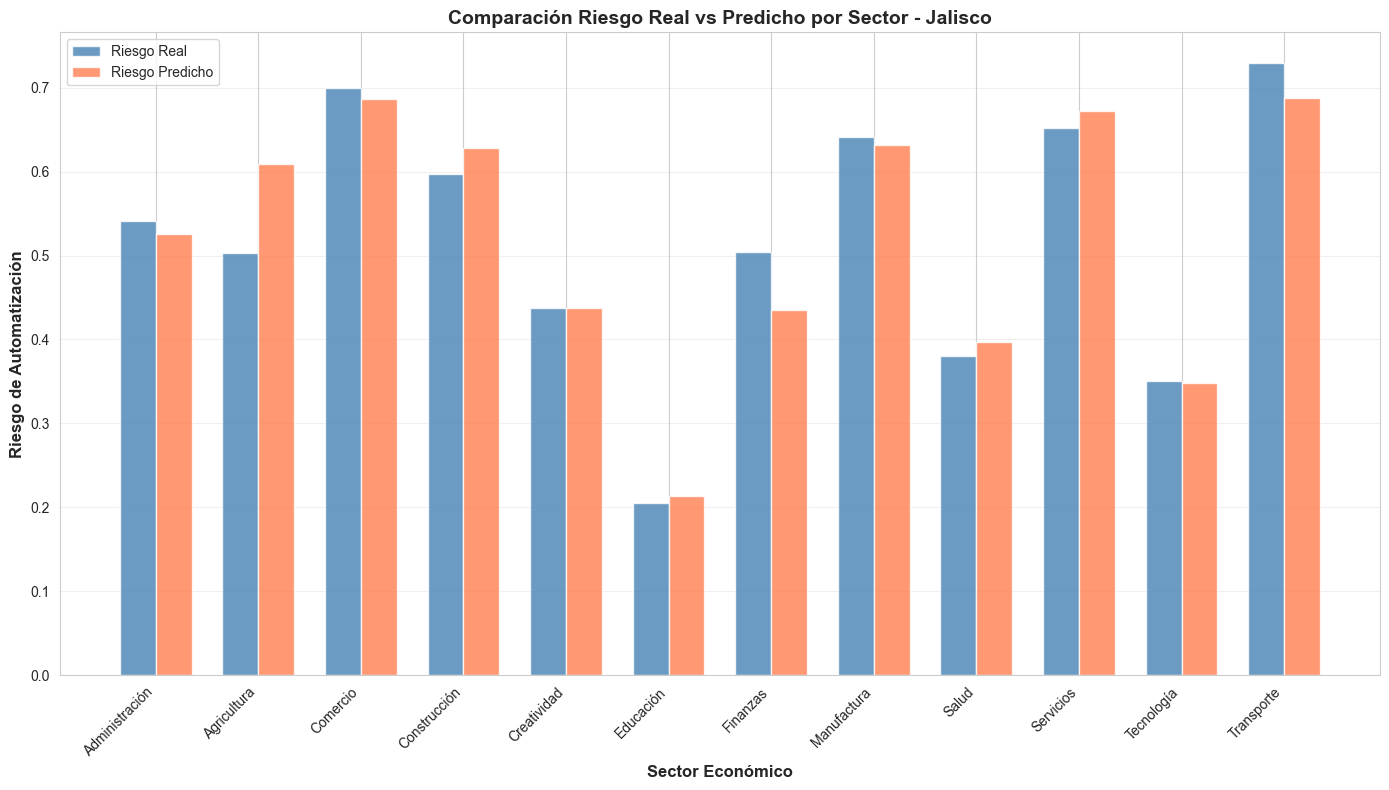

✓ Visualización 1 guardada


In [30]:
# Visualización 1: Comparación Riesgo Real vs Predicho por Sector
sector_stats = df_vis.groupby('sector').agg({
    'riesgo_automatizacion': 'mean',
    'prediction': 'mean'
}).reset_index()

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(sector_stats))
width = 0.35

bars1 = ax.bar(x - width/2, sector_stats['riesgo_automatizacion'], width, 
               label='Riesgo Real', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, sector_stats['prediction'], width, 
               label='Riesgo Predicho', color='coral', alpha=0.8)

ax.set_xlabel('Sector Económico', fontsize=12, fontweight='bold')
ax.set_ylabel('Riesgo de Automatización', fontsize=12, fontweight='bold')
ax.set_title('Comparación Riesgo Real vs Predicho por Sector - Jalisco', 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(sector_stats['sector'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('viz_1_riesgo_por_sector.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 1 guardada")

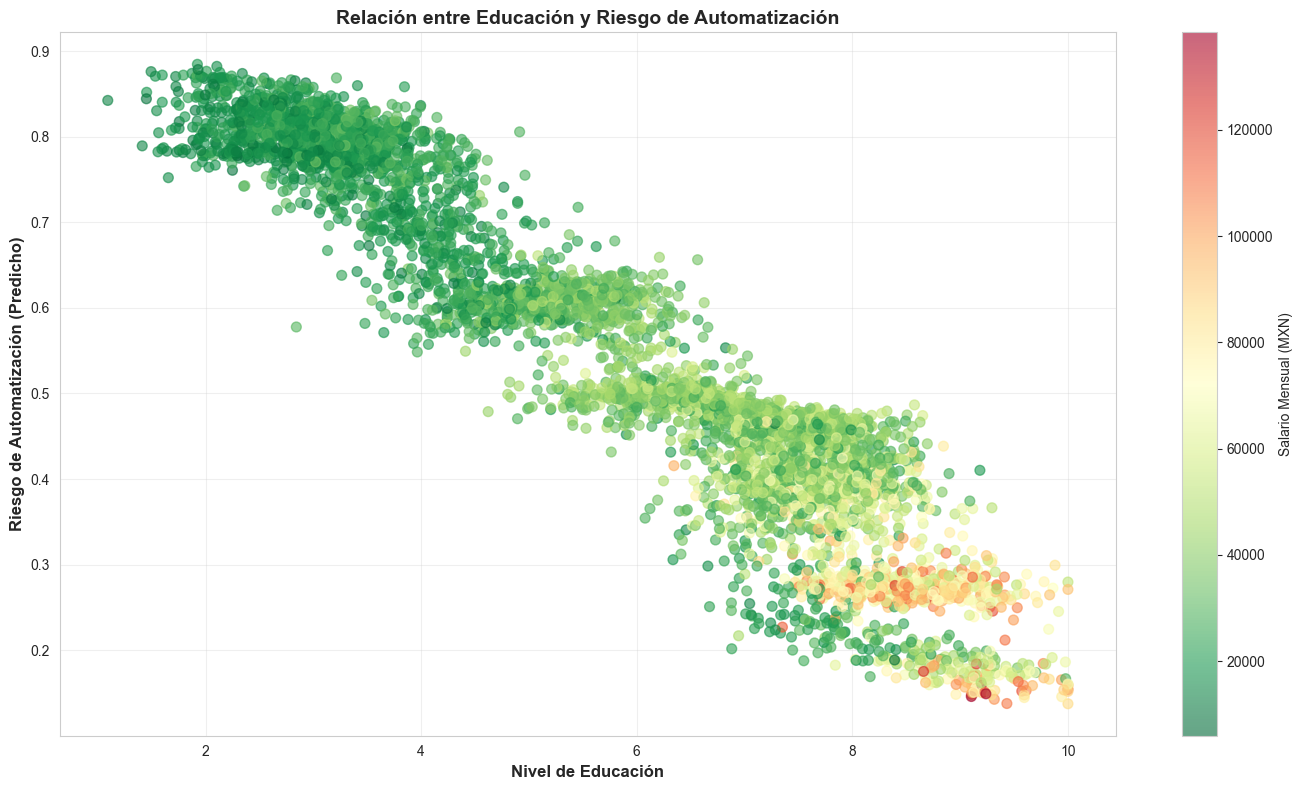

✓ Visualización 2 guardada


In [33]:
# Visualización 2: Scatter Plot - Educación vs Riesgo
plt.figure(figsize=(14, 8))

# Asegurar que sea pandas DataFrame
if not isinstance(df_vis, pd.DataFrame):
    df_vis = df_vis.toPandas()

# Muestreo para visualización (calcular tamaño sin usar min())
total_rows = len(df_vis)
sample_size = 5000 if total_rows > 5000 else total_rows
df_sample = df_vis.sample(n=sample_size, random_state=42)

scatter = plt.scatter(
    df_sample['nivel_educacion'],
    df_sample['prediction'],
    c=df_sample['salario_mensual'],
    cmap='RdYlGn_r',
    alpha=0.6,
    s=50
)

plt.colorbar(scatter, label='Salario Mensual (MXN)')
plt.xlabel('Nivel de Educación', fontsize=12, fontweight='bold')
plt.ylabel('Riesgo de Automatización (Predicho)', fontsize=12, fontweight='bold')
plt.title('Relación entre Educación y Riesgo de Automatización', 
          fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('viz_2_educacion_vs_riesgo.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 2 guardada")

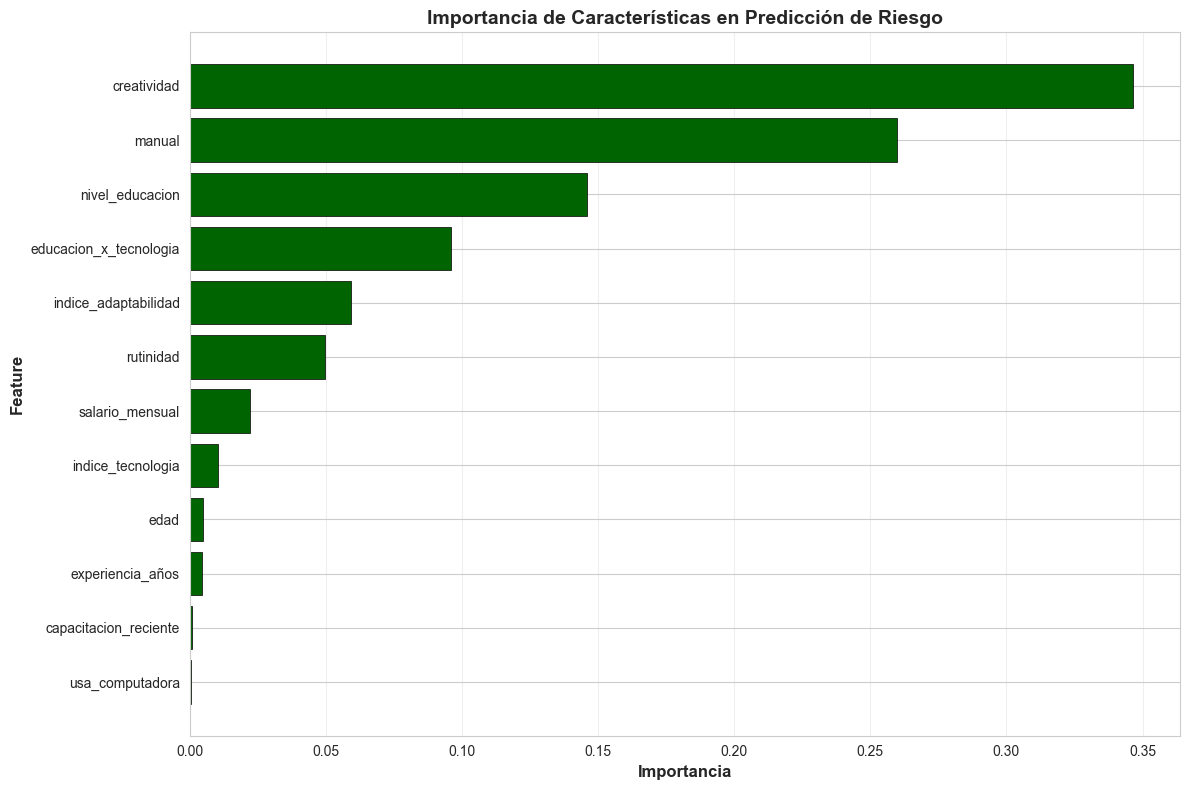

✓ Visualización 3 guardada


In [34]:
# Visualización 3: Feature Importance
plt.figure(figsize=(12, 8))

bars = plt.barh(importance_df['Feature'], importance_df['Importance'],
                color='darkgreen', edgecolor='black', linewidth=0.5)

plt.xlabel('Importancia', fontsize=12, fontweight='bold')
plt.ylabel('Feature', fontsize=12, fontweight='bold')
plt.title('Importancia de Características en Predicción de Riesgo', 
          fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('viz_3_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 3 guardada")

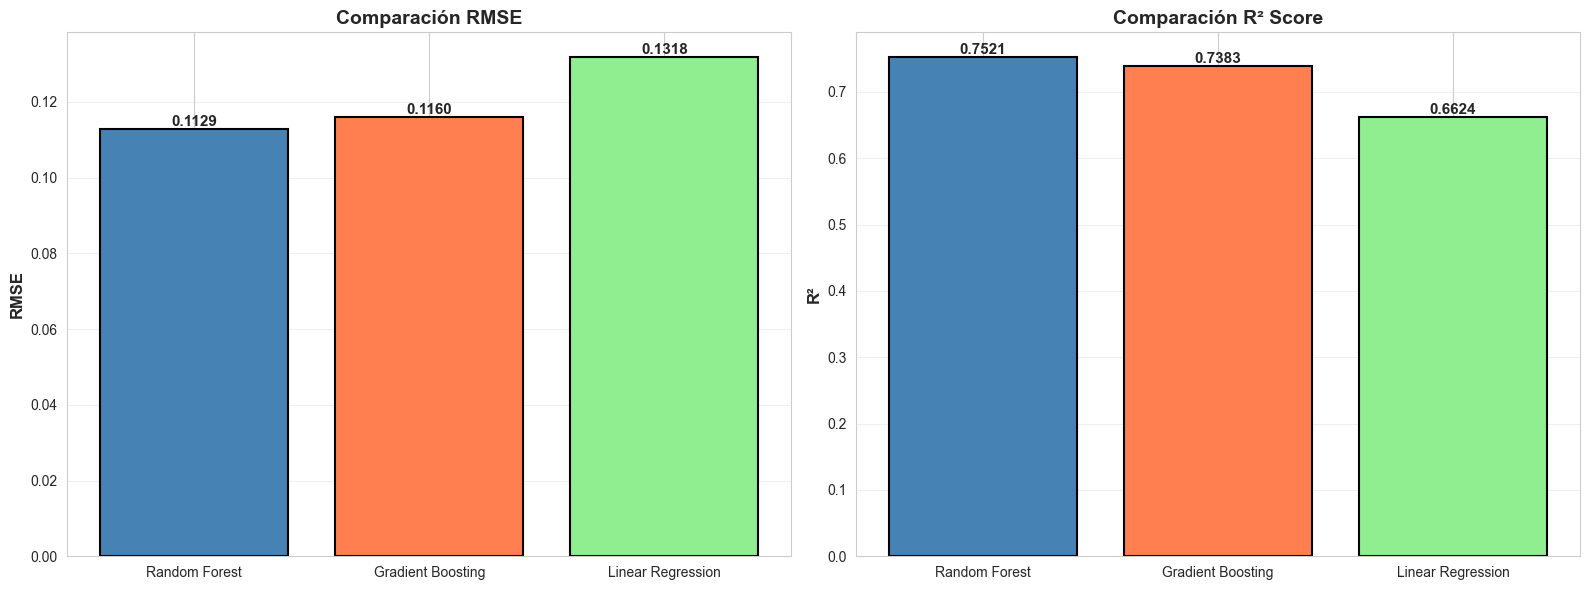

✓ Visualización 4 guardada


In [35]:
# Visualización 4: Comparación de Modelos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# RMSE
bars1 = axes[0].bar(resultados_modelos['Modelo'], resultados_modelos['RMSE'],
                    color=['steelblue', 'coral', 'lightgreen'],
                    edgecolor='black', linewidth=1.5)

for bar in bars1:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.4f}',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[0].set_ylabel('RMSE', fontsize=12, fontweight='bold')
axes[0].set_title('Comparación RMSE', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)

# R²
bars2 = axes[1].bar(resultados_modelos['Modelo'], resultados_modelos['R²'],
                    color=['steelblue', 'coral', 'lightgreen'],
                    edgecolor='black', linewidth=1.5)

for bar in bars2:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height,
                 f'{height:.4f}',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[1].set_ylabel('R²', fontsize=12, fontweight='bold')
axes[1].set_title('Comparación R² Score', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('viz_4_comparacion_modelos.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualización 4 guardada")

In [36]:
# Visualización 5: Top 10 Ocupaciones en Riesgo (Interactiva con Plotly)
top_riesgo = df_vis.groupby(['ocupacion', 'sector'])['prediction'].mean().reset_index()
top_riesgo = top_riesgo.sort_values('prediction', ascending=False).head(10)

fig = px.bar(
    top_riesgo,
    x='prediction',
    y='ocupacion',
    color='sector',
    orientation='h',
    title='Top 10 Ocupaciones con Mayor Riesgo de Automatización en Jalisco',
    labels={'prediction': 'Riesgo Predicho', 'ocupacion': 'Ocupación'},
    color_discrete_sequence=px.colors.qualitative.Set3
)

fig.update_layout(
    height=600,
    font=dict(size=12),
    title_font_size=16
)

fig.write_html('viz_5_top_ocupaciones_riesgo.html')
fig.show()

print("✓ Visualización 5 guardada (HTML interactivo)")

✓ Visualización 5 guardada (HTML interactivo)


## 10. Recomendaciones de Política Pública

In [37]:
# Análisis para recomendaciones
# Convertir datos de impacto a pandas
impacto_pd = impacto_sector.toPandas()

print("="*100)
print("RECOMENDACIONES DE POLÍTICA PÚBLICA PARA JALISCO")
print("="*100)

print("\n1. SECTORES PRIORITARIOS PARA INTERVENCIÓN:")
print("-" * 80)
sectores_riesgo = impacto_pd.nlargest(3, 'porcentaje_en_riesgo')
for idx, row in sectores_riesgo.iterrows():
    print(f"\n  • {row['sector']}:")
    print(f"    - Trabajadores en riesgo: {row['trabajadores_alto_riesgo']:,.0f} ({row['porcentaje_en_riesgo']:.1f}%)")
    print(f"    - Riesgo promedio: {row['riesgo_promedio']:.2f}")
    print(f"    - Salario promedio: ${row['salario_promedio']:,.2f} MXN")

print("\n\n2. PROGRAMAS DE CAPACITACIÓN RECOMENDADOS:")
print("-" * 80)
print("  • Habilidades Digitales Básicas (para sectores de alto riesgo)")
print("  • Programación y Análisis de Datos (para reconversión laboral)")
print("  • Creatividad y Resolución de Problemas (áreas difíciles de automatizar)")
print("  • Gestión de Tecnologías Emergentes (IA, IoT, Automatización)")

print("\n\n3. INVERSIÓN EN EDUCACIÓN:")
print("-" * 80)
print("  • Aumentar matriculación en educación terciaria en áreas STEM")
print("  • Fortalecer educación técnica y vocacional")
print("  • Programas de educación continua para trabajadores adultos")

print("\n\n4. INCENTIVOS PARA EMPRESAS:")
print("-" * 80)
print("  • Subsidios para capacitación de empleados")
print("  • Apoyo en transición tecnológica responsable")
print("  • Programas de mentoría y actualización profesional")

print("\n" + "="*100)

RECOMENDACIONES DE POLÍTICA PÚBLICA PARA JALISCO

1. SECTORES PRIORITARIOS PARA INTERVENCIÓN:
--------------------------------------------------------------------------------

  • Transporte:
    - Trabajadores en riesgo: 2,945 (61.4%)
    - Riesgo promedio: 0.69
    - Salario promedio: $29,007.24 MXN

  • Agricultura:
    - Trabajadores en riesgo: 1,475 (50.9%)
    - Riesgo promedio: 0.61
    - Salario promedio: $31,316.12 MXN

  • Comercio:
    - Trabajadores en riesgo: 2,367 (49.1%)
    - Riesgo promedio: 0.69
    - Salario promedio: $23,091.70 MXN


2. PROGRAMAS DE CAPACITACIÓN RECOMENDADOS:
--------------------------------------------------------------------------------
  • Habilidades Digitales Básicas (para sectores de alto riesgo)
  • Programación y Análisis de Datos (para reconversión laboral)
  • Creatividad y Resolución de Problemas (áreas difíciles de automatizar)
  • Gestión de Tecnologías Emergentes (IA, IoT, Automatización)


3. INVERSIÓN EN EDUCACIÓN:
------------------

## 11. Exportar Resultados

In [38]:
# Exportar resultados principales
print("Exportando resultados...\n")

# 1. Comparación de modelos
resultados_modelos.to_csv('resultado_comparacion_modelos.csv', index=False)
print("✓ resultado_comparacion_modelos.csv")

# 2. Feature importance
importance_df.to_csv('resultado_feature_importance.csv', index=False)
print("✓ resultado_feature_importance.csv")

# 3. Impacto por sector
impacto_pd.to_csv('resultado_impacto_sectores.csv', index=False)
print("✓ resultado_impacto_sectores.csv")

# 4. Top ocupaciones en riesgo
top_riesgo.to_csv('resultado_top_ocupaciones_riesgo.csv', index=False)
print("✓ resultado_top_ocupaciones_riesgo.csv")

# 5. Análisis por ocupación (convertir de Spark)
analisis_ocupacion.toPandas().to_csv('resultado_analisis_ocupaciones.csv', index=False)
print("✓ resultado_analisis_ocupaciones.csv")

print("\n✓ Todos los resultados exportados exitosamente")

Exportando resultados...

✓ resultado_comparacion_modelos.csv
✓ resultado_feature_importance.csv
✓ resultado_impacto_sectores.csv
✓ resultado_top_ocupaciones_riesgo.csv
✓ resultado_analisis_ocupaciones.csv

✓ Todos los resultados exportados exitosamente


## 12. Conclusiones del Análisis

## 13. Resumen Ejecutivo

In [39]:
# Generar resumen ejecutivo
print("="*100)
print("RESUMEN EJECUTIVO - PREDICCIÓN DE RIESGO DE AUTOMATIZACIÓN LABORAL EN JALISCO")
print("="*100)

print(f"\n📊 DATOS PROCESADOS:")
print(f"  • Total de registros analizados: {df_ml.count():,}")
print(f"  • Ocupaciones evaluadas: {df_ocupaciones_expandido['ocupacion'].nunique()}")
print(f"  • Sectores económicos: {df_ocupaciones_expandido['sector'].nunique()}")
print(f"  • Features utilizadas: {len(feature_cols)}")
print(f"  • Fuentes de datos: Banco Mundial, O*NET (simulado), ENOE (simulado)")

print(f"\n🤖 MODELOS ENTRENADOS:")
print(f"  1. Random Forest Regression - R²: {r2_rf:.4f}")
print(f"  2. Gradient Boosting Trees - R²: {r2_gbt:.4f}")
print(f"  3. Linear Regression - R²: {r2_lr:.4f}")

print(f"\n🏆 MEJOR MODELO: {mejor_modelo}")
print(f"  • R² Score: {mejor_r2:.4f}")
print(f"  • RMSE: {resultados_modelos.loc[mejor_idx, 'RMSE']:.4f}")
print(f"  • MAE: {resultados_modelos.loc[mejor_idx, 'MAE']:.4f}")

print(f"\n🔑 TOP 3 FEATURES MÁS IMPORTANTES:")
for i, row in importance_df.head(3).iterrows():
    print(f"  {i+1}. {row['Feature']}: {row['Importance']:.4f}")

print(f"\n⚠️ SECTORES MÁS VULNERABLES:")
for i, row in impacto_pd.nlargest(3, 'porcentaje_en_riesgo').iterrows():
    print(f"  • {row['sector']}: {row['porcentaje_en_riesgo']:.1f}% en alto riesgo")

print(f"\n📁 ARCHIVOS GENERADOS:")
print(f"  • 5 visualizaciones (PNG + HTML interactivo)")
print(f"  • 5 archivos de resultados (CSV)")
print(f"  • Modelos entrenados con Spark MLlib")

print(f"\n✨ TECNOLOGÍAS UTILIZADAS:")
print(f"  • Apache Spark {spark.version} - Procesamiento distribuido")
print(f"  • Spark MLlib - Machine Learning escalable")
print(f"  • PySpark.Pandas - Análisis con sintaxis familiar")
print(f"  • API del Banco Mundial - Indicadores económicos")
print(f"  • Matplotlib, Seaborn, Plotly - Visualizaciones")

print("\n" + "="*100)
print("CHALLENGE AVANZADO COMPLETADO EXITOSAMENTE")
print("Relación directa con tesis: Predicción de Automatización Laboral en Jalisco")
print("="*100)

RESUMEN EJECUTIVO - PREDICCIÓN DE RIESGO DE AUTOMATIZACIÓN LABORAL EN JALISCO

📊 DATOS PROCESADOS:
  • Total de registros analizados: 50,335
  • Ocupaciones evaluadas: 38
  • Sectores económicos: 12
  • Features utilizadas: 12
  • Fuentes de datos: Banco Mundial, O*NET (simulado), ENOE (simulado)

🤖 MODELOS ENTRENADOS:
  1. Random Forest Regression - R²: 0.7521
  2. Gradient Boosting Trees - R²: 0.7383
  3. Linear Regression - R²: 0.6624

🏆 MEJOR MODELO: Random Forest
  • R² Score: 0.7521
  • RMSE: 0.1129
  • MAE: 0.0903

🔑 TOP 3 FEATURES MÁS IMPORTANTES:
  3. creatividad: 0.3464
  4. manual: 0.2596
  1. nivel_educacion: 0.1461

⚠️ SECTORES MÁS VULNERABLES:
  • Transporte: 61.4% en alto riesgo
  • Agricultura: 50.9% en alto riesgo
  • Comercio: 49.1% en alto riesgo

📁 ARCHIVOS GENERADOS:
  • 5 visualizaciones (PNG + HTML interactivo)
  • 5 archivos de resultados (CSV)
  • Modelos entrenados con Spark MLlib

✨ TECNOLOGÍAS UTILIZADAS:
  • Apache Spark 3.5.6 - Procesamiento distribuido
  

In [ ]:
# Detener sesión de Spark
spark.stop()
print("\n✓ Sesión de Spark detenida correctamente")
print("\n🎓 Análisis completado. Listo para presentación.")